In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244080122

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()} | {platform.machine()} | {platform.system()} | {uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID} - {MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] base
[学号] 20244080122
[机器指纹] a0f1d52867d1286d
[RUN_ID] 20244080122 - a0f1d52867d1286d


In [2]:
import sys
print(sys.executable)

d:\Miniconda3\envs\exp02\python.exe


In [3]:
# ==========实验1 NumPy数组、数据类型与索引==========
import numpy as np

# 1. 创建整数、浮点数、布尔 ndarray，输出dtype、shape、ndim
arr_int = np.array([1,2,3,4])
arr_float = np.array([1.1, 2.2, 3.3])
arr_bool = np.array([True, False, True])

print("====整数数组====")
print(f"数组:{arr_int}, dtype:{arr_int.dtype}, shape:{arr_int.shape}, ndim:{arr_int.ndim}")
print("====浮点数数组====")
print(f"数组:{arr_float}, dtype:{arr_float.dtype}, shape:{arr_float.shape}, ndim:{arr_float.ndim}")
print("====布尔数组====")
print(f"数组:{arr_bool}, dtype:{arr_bool.dtype}, shape:{arr_bool.shape}, ndim:{arr_bool.ndim}")

# 2. np.arange(12) 改变形状
a = np.arange(12)
a1 = a.reshape(3,4)
a2 = a.reshape(2,3,2)
print("\n====原数组 arange(12)====")
print(a)
print("\n====reshape(3,4)====")
print(a1)
print("\n====reshape(2,3,2)====")
print(a2)

#3. 对(3,4)数组索引
print("\n====索引操作（a1 为(3,4)数组）====")
row2 = a1[1,:]          #取第2行（下标从0开始）
col1_3 = a1[:,0:3]      #第1~3列
gt6 = a1[a1>6]
print("第2行：",row2, "shape:",row2.shape)
print("第1至3列：\n",col1_3, "shape:",col1_3.shape)
print("大于6的元素：",gt6, "shape:",gt6.shape)

#4.逻辑布尔索引
b = np.arange(10)
sel1 = b[(b<2) | (b>7)]
sel2 = b[(b>3) & (b<7)]
print("\n====逻辑索引====")
print("小于2或者大于7：", sel1)
print("大于3并且小于7：", sel2)

#5.逐元素乘法 * /multiply 和矩阵乘法 @ /matmul
m1 = np.array([[1,2],[3,4]])
m2 = np.array([[5,6],[7,8]])
elem_mul = m1 * m2
elem_mul2 = np.multiply(m1,m2)
mat_mul = m1 @ m2
mat_mul2 = np.matmul(m1,m2)

print("\n====逐元素乘法 * ====")
print(elem_mul)
print("\n====np.multiply逐元素乘法====")
print(elem_mul2)
print("\n====矩阵乘法 @ ====")
print(mat_mul)
print("\n====np.matmul矩阵乘法====")
print(mat_mul2)



====整数数组====
数组:[1 2 3 4], dtype:int64, shape:(4,), ndim:1
====浮点数数组====
数组:[1.1 2.2 3.3], dtype:float64, shape:(3,), ndim:1
====布尔数组====
数组:[ True False  True], dtype:bool, shape:(3,), ndim:1

====原数组 arange(12)====
[ 0  1  2  3  4  5  6  7  8  9 10 11]

====reshape(3,4)====
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

====reshape(2,3,2)====
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

====索引操作（a1 为(3,4)数组）====
第2行： [4 5 6 7] shape: (4,)
第1至3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape: (3, 3)
大于6的元素： [ 7  8  9 10 11] shape: (5,)

====逻辑索引====
小于2或者大于7： [0 1 8 9]
大于3并且小于7： [4 5 6]

====逐元素乘法 * ====
[[ 5 12]
 [21 32]]

====np.multiply逐元素乘法====
[[ 5 12]
 [21 32]]

====矩阵乘法 @ ====
[[19 22]
 [43 50]]

====np.matmul矩阵乘法====
[[19 22]
 [43 50]]


### 实验1：NumPy数组、数据类型与索引
1. ndarray数组要求内部元素类型统一，相比Python列表存储更高效；通过`dtype`查看类型、`shape`查看维度大小、`ndim`查看维数。
2. `reshape()`用来改变数组形状，要求所有维度相乘等于数组总元素数量。
3. 索引：支持位置切片、布尔条件索引；下标从0开始。
4. 运算符`*`与`np.multiply()`是**逐元素相乘**；`@`与`np.matmul()`是标准**数学矩阵乘法**，二者规则不同。


In [4]:
# ==========实验2：随机抽样、统计与缺失值==========
import numpy as np
import pandas as pd

np.random.seed(42) #固定随机种子，结果可复现

#1.生成1000个成绩，均值70，标准差10，clip限制0‑100
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0,100)
print("====模拟成绩统计====")
print(f"样本数:{len(scores)}")
print(f"最小值:{scores.min():.2f}")
print(f"最大值:{scores.max():.2f}")
print(f"均值:{scores.mean():.2f}")
print(f"标准差:{scores.std():.2f}")
print(f"极差:{scores.max()-scores.min():.2f}")

#2.不放回抽样，均匀抽样 & 加权抽样
pop = np.arange(1,11)
sample_uniform = np.random.choice(pop,size=5, replace=False)
#权重和整数大小成正比
p_weight = pop / pop.sum()
sample_weighted = np.random.choice(pop,size=5, replace=False, p=p_weight)
print("\n====抽样====")
print("均匀不放回抽样：", sample_uniform)
print("按大小比例加权抽样：", sample_weighted)

#3.随机排列，不修改原数组 vs原地打乱
arr_ori = np.array([1,2,3,4,5])
arr_copy_shuffle = np.random.permutation(arr_ori)
print("\n====permutation(不改变原数组)====")
print("原数组:",arr_ori)
print("permutation结果:", arr_copy_shuffle)

arr_inplace = np.array([1,2,3,4,5])
np.random.shuffle(arr_inplace)
print("\n====shuffle原地打乱====")
print("shuffle之后原数组：", arr_inplace)

#4.设置nan缺失值
scores_nan = scores.copy()
scores_nan[[9,19,29]] = np.nan #下标9、19、29设为缺失
cnt_nan = np.sum(np.isnan(scores_nan))
mean_all = np.mean(scores_nan)
mean_ignore_nan = np.nanmean(scores_nan)
print("\n====缺失值处理====")
print(f"缺失值个数：{cnt_nan}")
print(f"普通mean(含nan): {mean_all}")
print(f"nanmean忽略缺失值: {mean_ignore_nan:.2f}")

#保存DataFrame，给后面实验使用
df_exp2 = pd.DataFrame({
    "score": scores_nan,
    "index": np.arange(len(scores_nan))
})
print("\nexp2表格前5行：")
print(df_exp2.head())


====模拟成绩统计====
样本数:1000
最小值:37.59
最大值:100.00
均值:70.18
标准差:9.76
极差:62.41

====抽样====
均匀不放回抽样： [ 4  9  2  6 10]
按大小比例加权抽样： [10  2  8  9  6]

====permutation(不改变原数组)====
原数组: [1 2 3 4 5]
permutation结果: [5 1 3 2 4]

====shuffle原地打乱====
shuffle之后原数组： [1 5 2 4 3]

====缺失值处理====
缺失值个数：3
普通mean(含nan): nan
nanmean忽略缺失值: 70.20

exp2表格前5行：
       score  index
0  74.967142      0
1  68.617357      1
2  76.476885      2
3  85.230299      3
4  67.658466      4


### 实验2：随机抽样、统计与缺失值
1. 使用`np.random.normal()`生成正态分布样本，`np.clip()`把数值限制在指定区间；可以用mean、std、min、max做统计计算。
2. `np.random.choice()`支持有放回/无放回抽样，还可以设置权重实现加权抽样。
3. `np.random.permutation()`返回新打乱数组，不改动原数据；`np.random.shuffle()`原地修改数组。
4. NaN是缺失标记，直接`np.mean()`遇到NaN结果为NaN；`np.nanmean()`会自动跳过缺失值计算均值。


====线性方程组求解====
解：x=2.00, y=3.00
代入验证 A@sol =  [9. 8.]

====方程 x² - 2 = 0 求根====
正根：1.4142，是否成功：True
负根：-1.4142，是否成功：True

====函数极小值求解====
极小点 x = -0.5000
极小值 f(x) = 1.7500

====独立样本t检验====
t统计量：-8.5515，p值：0.0000


d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20989 (\N{CJK UNIFIED IDEOGRAPH-51FD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 22270 (\N{CJK UNIFIED IDEOGRAPH-56FE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20687 (\N{CJK UNIFIED IDEOGRAPH-50CF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


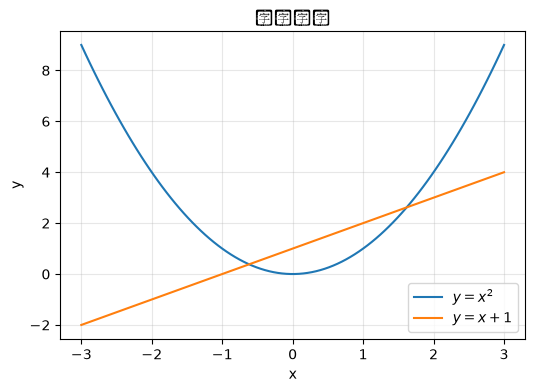

In [5]:
# ==========实验3：SciPy数值计算 + Matplotlib绘图==========
import numpy as np
from scipy import linalg
from scipy.optimize import root, minimize
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt

# 1. 求解线性方程组：3x + y = 9，x + 2y = 8
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])
sol = linalg.solve(A, b)
print("====线性方程组求解====")
print(f"解：x={sol[0]:.2f}, y={sol[1]:.2f}")
print("代入验证 A@sol = ", A @ sol)

# 2. 求方程 x² - 2 = 0 的根
def f(x):
    return x ** 2 - 2

res_pos = root(f, x0=1.5)
res_neg = root(f, x0=-1.5)
print("\n====方程 x² - 2 = 0 求根====")
print(f"正根：{res_pos.x[0]:.4f}，是否成功：{res_pos.success}")
print(f"负根：{res_neg.x[0]:.4f}，是否成功：{res_neg.success}")

# 3. 求函数 f(x)=x² + x + 2 的极小值
def fun_min(x):
    return x ** 2 + x + 2

res_min = minimize(fun_min, x0=0)
print("\n====函数极小值求解====")
print(f"极小点 x = {res_min.x[0]:.4f}")
print(f"极小值 f(x) = {res_min.fun:.4f}")

# 4. 独立样本t检验
np.random.seed(42)
s1 = np.random.normal(0, 1, 100)
s2 = np.random.normal(1, 1, 100)
t_stat, p_val = ttest_ind(s1, s2)
print("\n====独立样本t检验====")
print(f"t统计量：{t_stat:.4f}，p值：{p_val:.4f}")

# 5. Matplotlib绘制两条曲线
x = np.linspace(-3, 3, 100)
y1 = x ** 2
y2 = x + 1
plt.figure(figsize=(6,4))
plt.plot(x, y1, label="$y=x^2$")
plt.plot(x, y2, label="$y=x+1$")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.title("函数图像")
plt.show()


### 实验3：SciPy数值计算与Matplotlib绘图
1. `scipy.linalg.solve()` 求解线性方程组。
2. `scipy.optimize.root()` 用于非线性方程求根；`minimize()` 寻找函数极小值。
3. `scipy.stats.ttest_ind()` 实现两独立样本t检验，p值用来判断两组样本均值差异是否显著。
4. Matplotlib用于可视化绘图，支持曲线绘制、图例、网格、坐标轴标注等。


In [6]:
# ==========实验4：Pandas数据表操作==========
import pandas as pd
import numpy as np

# 复用实验2的数据
np.random.seed(42)
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0,100)
scores_nan = scores.copy()
scores_nan[[9,19,29]] = np.nan

df = pd.DataFrame({
    "score": scores_nan,
    "index": np.arange(len(scores_nan))
})

# 1.基础信息查看
print("====数据基本信息 info====")
print(df.info())
print("\n====描述性统计 describe====")
print(df.describe())

# 2.缺失值统计
print("\n====缺失值统计====")
print(df.isnull().sum())

# 3.缺失值填充
df_fill_mean = df.copy()
df_fill_mean["score"] = df_fill_mean["score"].fillna(df_fill_mean["score"].mean())
print("\n====均值填充后前10行====")
print(df_fill_mean.head(10))

# 4.条件筛选
df_pass = df_fill_mean[df_fill_mean["score"] >= 60]
print("\n====及格样本数量：", len(df_pass))

# 5.新增一列等级
def get_level(s):
    if s >= 90:
        return "A"
    elif s >= 80:
        return "B"
    elif s >=70:
        return "C"
    elif s >=60:
        return "D"
    else:
        return "E"

df_fill_mean["level"] = df_fill_mean["score"].apply(get_level)
print("\n====各等级计数====")
print(df_fill_mean["level"].value_counts())

# 6.分组统计
group_stat = df_fill_mean.groupby("level")["score"].agg(["mean","std","count"])
print("\n====分组统计====")
print(group_stat)


====数据基本信息 info====
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   score   997 non-null    float64
 1   index   1000 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 15.8 KB
None

====描述性统计 describe====
            score        index
count  997.000000  1000.000000
mean    70.196207   499.500000
std      9.762222   288.819436
min     37.587327     0.000000
25%     63.534271   249.750000
50%     70.260911   499.500000
75%     76.487099   749.250000
max    100.000000   999.000000

====缺失值统计====
score    3
index    0
dtype: int64

====均值填充后前10行====
       score  index
0  74.967142      0
1  68.617357      1
2  76.476885      2
3  85.230299      3
4  67.658466      4
5  67.658630      5
6  85.792128      6
7  77.674347      7
8  65.305256      8
9  70.196207      9

====及格样本数量： 854

====各等级计数====
level
C    357
D    342
E    146
B    131
A     24
Name: c

### 实验4：Pandas数据表操作
1. DataFrame是表格型数据结构，`info()`查看结构，`describe()`输出统计摘要。
2. `isnull()`检测缺失值；`fillna()`对NaN进行填充。
3. 支持布尔条件筛选数据，`apply()`自定义函数生成新列。
4. `groupby()`分组，搭配agg实现分组聚合统计。


====学生成绩汇总====
             math     english       total
count  200.000000  200.000000  200.000000
mean    74.443316   72.772122  147.215439
std     10.997681    9.629217   15.311112
min     43.563059   39.587327  101.311307
25%     66.538468   66.004013  136.684893
50%     74.949697   72.772122  147.922723
75%     81.010230   78.801866  157.514158
max    100.000000  100.000000  187.734371


d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 23398 (\N{CJK UNIFIED IDEOGRAPH-5B66}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 33521 (\N{CJK UNIFIED IDEOGRAPH-82F1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 35821 (\N{CJK UNIFIED IDEOGRAPH-8BED}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu San

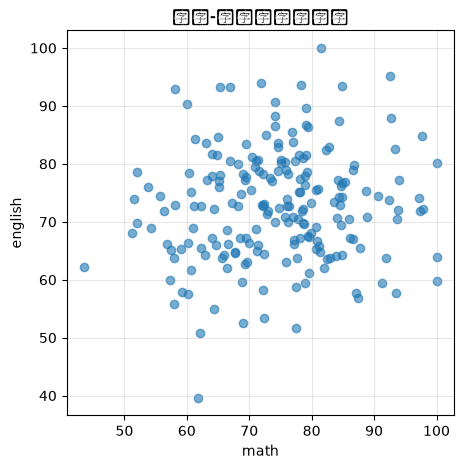

d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 24067 (\N{CJK UNIFIED IDEOGRAPH-5E03}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Miniconda3\envs\exp02\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 30452 (\N{CJK UNIFIED IDEOGRAPH-76F4}) missing from font(s) DejaVu San

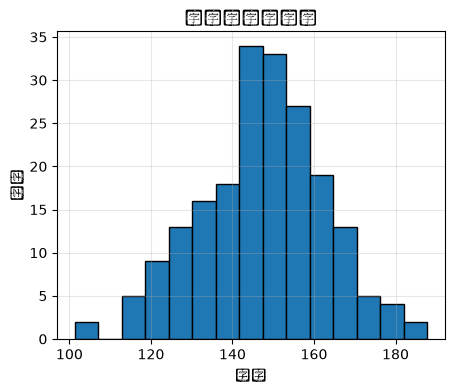


数学和英语相关系数：0.0980


In [7]:
# ==========实验5：综合小案例==========
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
# 生成学生数据
n = 200
math = np.random.normal(75,12,n)
eng = np.random.normal(72,10,n)
math = np.clip(math,0,100)
eng = np.clip(eng,0,100)
eng[[5,15,25]] = np.nan

stu_df = pd.DataFrame({
    "math":math,
    "english":eng
})
# 填充英语缺失值
stu_df["english"] = stu_df["english"].fillna(stu_df["english"].mean())
stu_df["total"] = stu_df["math"] + stu_df["english"]

print("====学生成绩汇总====")
print(stu_df.describe())

# 绘图：数学、英语成绩散点图
plt.figure(figsize=(5,5))
plt.scatter(stu_df["math"], stu_df["english"], alpha=0.6)
plt.xlabel("math")
plt.ylabel("english")
plt.title("数学-英语成绩散点图")
plt.grid(alpha=0.3)
plt.show()

# 总分直方图
plt.figure(figsize=(5,4))
plt.hist(stu_df["total"], bins=15, edgecolor="black")
plt.xlabel("总分")
plt.ylabel("人数")
plt.title("总分分布直方图")
plt.grid(alpha=0.3)
plt.show()

corr = stu_df["math"].corr(stu_df["english"])
print(f"\n数学和英语相关系数：{corr:.4f}")


### 实验5：综合案例
综合运用numpy生成模拟数据、pandas做数据清洗、字段计算、统计，matplotlib绘制散点图和直方图，并计算变量相关系数，完成一套简单数据分析流程。
